# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [1]:
# ячейка с импортами - дополняйте по своему желанию
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

**Вывод:**

1. **z-тест** — среднее одной выборки сравнивается с заданным значением, а дисперсия процесса известна, поэтому статистика $Z = (\bar X - \mu_0) / (\sigma / \sqrt{n})$ при $H_0$ имеет стандартное нормальное распределение.
2. **t-тест (объединённый)** — две независимые группы с неизвестными, но равными дисперсиями: общую дисперсию оценивают по обеим выборкам сразу, статистика имеет $t$-распределение с $n_1 + n_2 - 2$ степенями свободы.
3. **Welch t-тест** — дисперсии неизвестны и не равны, поэтому каждая оценивается отдельно, а степени свободы считаются по формуле Уэлча–Саттертуэйта; объединённый тест здесь искажает уровень значимости.
4. **Однофакторный ANOVA** — один $F$-критерий (межгрупповая изменчивость против внутригрупповой) сравнивает сразу $k \ge 3$ средних без накопления ошибки I рода, как при серии попарных t-тестов. Равенство дисперсий для него заранее проверяют критерием Левена, а при значимом результате различающиеся пары находят с помощью Tukey HSD.
5. **Критерий хи-квадрат (согласия)** — сравнивает наблюдаемые частоты с ожидаемыми по распределению Пуассона; параметр $\lambda$ оценивается по выборке, поэтому число степеней свободы уменьшается на единицу.

### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [2]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50

alpha = 0.05
se = sigma / np.sqrt(n)
z_stat = (xbar - mu0) / se
p_value = 2 * stats.norm.sf(abs(z_stat))

z_crit = stats.norm.ppf(1 - alpha / 2)
ci_low, ci_high = xbar - z_crit * se, xbar + z_crit * se

print(f"z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% доверительный интервал для μ: [{ci_low:.5f}; {ci_high:.5f}] г")
print("H0 отвергается" if p_value < alpha else "H0 не отвергается")

z-статистика: 2.3570
p-value: 0.0184
95% доверительный интервал для μ: [3.00084; 3.00916] г
H0 отвергается


**Вывод:** $z \approx 2.357$, p-value $\approx 0.018 < 0.05$ — $H_0: \mu = 3.00$ отвергается. 95% доверительный интервал $[3.0008;\ 3.0092]$ г не содержит 3.00 и целиком лежит выше нормы: дозатор систематически передозирует примерно на 5 мг, поэтому его нужно перенастроить.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [3]:
A = np.array(
    [
        51.99,
        49.45,
        52.59,
        56.09,
        49.06,
        49.06,
        56.32,
        53.07,
        48.12,
        52.17,
        48.15,
        48.14,
        50.97,
        42.35,
        43.10,
    ]
)
B = np.array([48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73])

alpha = 0.05

# F-тест чувствителен к отклонениям от нормальности — сначала проверяем её
print(
    f"Шапиро-Уилк: p-value(A) = {stats.shapiro(A).pvalue:.4f}, "
    f"p-value(B) = {stats.shapiro(B).pvalue:.4f}"
)

levene_p = stats.levene(A, B).pvalue
df_a, df_b = len(A) - 1, len(B) - 1
f_stat = A.var(ddof=1) / B.var(ddof=1)
f_p_value = 2 * min(stats.f.cdf(f_stat, df_a, df_b), stats.f.sf(f_stat, df_a, df_b))
print(f"Критерий Левена: p-value = {levene_p:.4f}")
print(f"F-тест: F = {f_stat:.4f}, p-value = {f_p_value:.4f}")

# оба критерия не отвергают равенство дисперсий -> объединённый t-тест
equal_var = levene_p > alpha and f_p_value > alpha
t_test = stats.ttest_ind(A, B, equal_var=equal_var)
test_name = "Объединённый t-тест" if equal_var else "Welch t-тест"
print(f"{test_name}: t = {t_test.statistic:.4f}, p-value = {t_test.pvalue:.4f}")

ci = t_test.confidence_interval(confidence_level=1 - alpha)
print(f"Разность средних (A - B): {A.mean() - B.mean():.4f} MPa")
print(f"95% доверительный интервал для разности: [{ci.low:.4f}; {ci.high:.4f}] MPa")

Шапиро-Уилк: p-value(A) = 0.4201, p-value(B) = 0.3993
Критерий Левена: p-value = 0.5009
F-тест: F = 0.5656, p-value = 0.3271
Объединённый t-тест: t = 0.3171, p-value = 0.7541
Разность средних (A - B): 0.5870 MPa
95% доверительный интервал для разности: [-3.2428; 4.4168] MPa


**Вывод:** обе выборки согласуются с нормальным законом, и ни критерий Левена (p $\approx 0.50$), ни F-тест (p $\approx 0.33$) не отвергают равенство дисперсий, поэтому применён объединённый t-тест. Он не находит различий (t $\approx 0.32$, p $\approx 0.75 > 0.05$): разность средних 0.59 MPa, а её 95% интервал $[-3.24;\ 4.42]$ MPa содержит ноль — по этим данным прочность материалов A и B статистически не различается.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [4]:
before = np.array([7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9])
after = np.array([6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4])
diff = after - before

alpha = 0.01
shapiro_p = stats.shapiro(diff).pvalue
print(f"Шапиро-Уилк для разностей: p-value = {shapiro_p:.4f}")

# разности согласуются с нормальным законом (p > 0.05) -> парный t-тест;
# односторонняя H1: уровень глюкозы после приёма ниже (среднее разностей < 0)
t_test = stats.ttest_rel(after, before, alternative="less")
print(f"Парный t-тест: t = {t_test.statistic:.4f}, p-value = {t_test.pvalue:.2e}")
print(f"Средняя разность (после - до): {diff.mean():.2f} ммоль/л")
print("H0 отвергается" if t_test.pvalue < alpha else "H0 не отвергается")

Шапиро-Уилк для разностей: p-value = 0.1977
Парный t-тест: t = -7.9649, p-value = 1.15e-05
Средняя разность (после - до): -0.34 ммоль/л
H0 отвергается


**Вывод:** разности согласуются с нормальным законом (Шапиро-Уилк p $\approx 0.198 > 0.05$), поэтому выбран парный t-тест — он мощнее критерия Уилкоксона при выполненной нормальности. Односторонний тест даёт t $\approx -7.96$, p $\approx 1.1 \cdot 10^{-5} < 0.01$: после приёма лекарства уровень глюкозы достоверно снижается, в среднем на 0.34 ммоль/л.

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

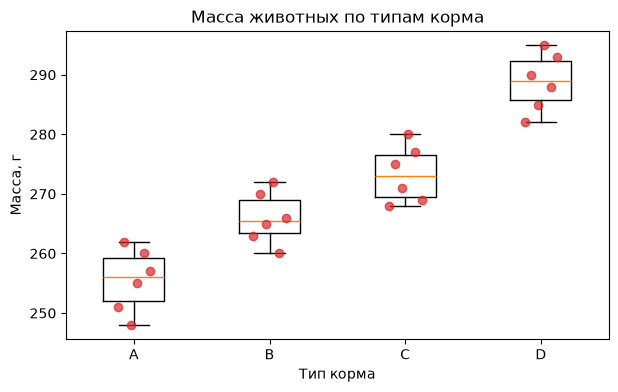

Шапиро-Уилк, корм A: p-value = 0.8799
Шапиро-Уилк, корм B: p-value = 0.9168
Шапиро-Уилк, корм C: p-value = 0.6488
Шапиро-Уилк, корм D: p-value = 0.9415
Критерий Левена: p-value = 0.9417
ANOVA: F = 49.9246, p-value = 1.80e-09
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------
Средняя масса: A — 255.50 г, B — 266.00 г, C — 273.33 г, D — 288.83 г


In [5]:
A = [251, 262, 248, 255, 260, 257]
B = [263, 270, 265, 272, 260, 266]
C = [268, 275, 271, 280, 277, 269]
D = [282, 290, 285, 295, 288, 293]

alpha = 0.05
groups = {"A": A, "B": B, "C": C, "D": D}

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(list(groups.values()), tick_labels=list(groups))
for pos, values in enumerate(groups.values(), start=1):
    offsets = np.linspace(-0.12, 0.12, len(values))  # разносим точки по горизонтали
    ax.scatter(pos + offsets, values, color="tab:red", alpha=0.7, zorder=3)
ax.set(title="Масса животных по типам корма", xlabel="Тип корма", ylabel="Масса, г")
plt.show()

for name, values in groups.items():
    print(f"Шапиро-Уилк, корм {name}: p-value = {stats.shapiro(values).pvalue:.4f}")
print(f"Критерий Левена: p-value = {stats.levene(*groups.values()).pvalue:.4f}")

anova = stats.f_oneway(*groups.values())
print(f"ANOVA: F = {anova.statistic:.4f}, p-value = {anova.pvalue:.2e}")

if anova.pvalue < alpha:
    masses = np.concatenate(list(groups.values()))
    labels = np.repeat(list(groups), [len(v) for v in groups.values()])
    print(pairwise_tukeyhsd(masses, labels, alpha=alpha))
    print(
        "Средняя масса:",
        ", ".join(f"{k} — {np.mean(v):.2f} г" for k, v in groups.items()),
    )

**Вывод:** в каждой группе распределение согласуется с нормальным (все p Шапиро-Уилка > 0.64), дисперсии однородны (Левен p $\approx 0.94$), так что допущения ANOVA выполнены. ANOVA значим (F $\approx 49.9$, p $\approx 1.8 \cdot 10^{-9}$), а по Tukey HSD корм D даёт массу достоверно выше всех остальных (+15.5 г к C, +22.8 г к B, +33.3 г к A, p-adj $\le 0.0001$) — **наиболее эффективен корм D**. Единственная незначимая пара — B и C (p-adj $\approx 0.07$).

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [6]:
conv_c, n_c = 85, 1000  # контроль
conv_v, n_v = 120, 1000  # тест

alpha = 0.05
for name, conv, n in [("Контроль", conv_c, n_c), ("Тест", conv_v, n_v)]:
    low, high = proportion_confint(conv, n, alpha=alpha, method="wilson")
    print(f"{name}: конверсия {conv / n:.3f}, интервал Уилсона [{low:.4f}; {high:.4f}]")

z_stat, p_value = proportions_ztest([conv_v, conv_c], [n_v, n_c])
print(f"z-тест для двух долей: z = {z_stat:.4f}, p-value = {p_value:.4f}")

# бутстрэп: пересэмплируем пользователей внутри каждой группы
np.random.seed(42)
n_boot = 10_000
control = np.arange(n_c) < conv_c  # True — конверсия
variant = np.arange(n_v) < conv_v
boot_c = np.random.choice(control, size=(n_boot, n_c)).mean(axis=1)
boot_v = np.random.choice(variant, size=(n_boot, n_v)).mean(axis=1)
diff_low, diff_high = np.percentile(boot_v - boot_c, [2.5, 97.5])

print(
    f"Точечная разность конверсий (тест - контроль): {conv_v / n_v - conv_c / n_c:.4f}"
)
print(f"95% бутстрэп-интервал для разности: [{diff_low:.4f}; {diff_high:.4f}]")

Контроль: конверсия 0.085, интервал Уилсона [0.0693; 0.1039]
Тест: конверсия 0.120, интервал Уилсона [0.1013; 0.1416]
z-тест для двух долей: z = 2.5803, p-value = 0.0099


Точечная разность конверсий (тест - контроль): 0.0350
95% бутстрэп-интервал для разности: [0.0090; 0.0610]


**Вывод:** конверсия контроля 8.5% (интервал Уилсона $[6.9\%;\ 10.4\%]$), теста — 12.0% ($[10.1\%;\ 14.2\%]$); интервалы немного пересекаются, но это не означает отсутствия различий — проверять нужно саму разность. z-тест для двух долей значим (z $\approx 2.58$, p $\approx 0.0099 < 0.05$), а бутстрэп-интервал разности $[0.9;\ 6.1]$ п.п. не содержит ноль при точечной оценке +3.5 п.п. Тестовый вариант стоит выкатывать.